# plutovizu — Thèmes, palettes, polices et export

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Données d'exemple

In [2]:
rng = np.random.default_rng(42)
n = 120
jours = np.arange(n)
effet_categorie = {'A': 150, 'B': -80, 'C': 40, 'D': -150}

ventes = pd.DataFrame({
    'date': pd.date_range('2024-01-01', periods=n, freq='D'),
    'categorie': rng.choice(list(effet_categorie), n),
    'temperature': rng.normal(27, 4, n).round(1),
})
# tendance + cycle mensuel + effet de la catégorie + bruit
ventes['ventes'] = (np.linspace(900, 1300, n) + 120 * np.sin(jours * 2 * np.pi / 30)
                    + ventes['categorie'].map(effet_categorie) + rng.normal(0, 40, n))
ventes['profit'] = ventes['ventes'] * 0.18 + rng.normal(0, 15, n)
ventes['visiteurs'] = (20 + 2.2 * ventes['temperature'] + rng.normal(0, 6, n)).round().astype(int)
ventes.head()

,date,categorie,temperature,ventes,profit,visiteurs
0,2024-01-01,A,23.5,1045.254467,161.794977,71
1,2024-01-02,D,30.9,789.743793,147.073815,96
2,2024-01-03,C,20.3,1047.771156,214.509061,65
3,2024-01-04,B,25.7,909.393564,140.682920,72
4,2024-01-05,B,27.7,906.185668,176.070840,77


## Données d'exemple

Jeux de données fictifs utilisés dans ce notebook.

In [3]:
hebdo = ventes.resample('W', on='date')[['ventes', 'profit']].mean().reset_index()

par_categorie = ventes.groupby('categorie', as_index=False)['ventes'].mean()

production = pd.DataFrame({'annee': ['2021', '2022', '2023', '2024'],
                           'Riz': [420, 455, 390, 480], 'Maïs': [310, 300, 335, 350],
                           'Mil': [180, 165, 190, 175]})

## Thèmes

36 thèmes : 15 maison (dont prezi), 5 styles seaborn et 16 morethemes (paquet optionnel). `theme_context` limite un thème à un bloc `with`.

In [4]:
{source: list_themes(source) for source in ['plutovizu', 'seaborn', 'morethemes']}

{'plutovizu': ['accessible',
  'arctic',
  'blueprint',
  'editorial',
  'forest',
  'ink',
  'neon',
  'ocean',
  'paper',
  'pastel',
  'pluto',
  'prezi',
  'sahel',
  'sunset',
  'terminal'],
 'seaborn': ['seaborn-dark',
  'seaborn-darkgrid',
  'seaborn-ticks',
  'seaborn-white',
  'seaborn-whitegrid'],
 'morethemes': ['darker',
  'ebonis',
  'economist',
  'ft',
  'greenwave',
  'lighter',
  'lumen',
  'minimal',
  'monoblue',
  'nature',
  'nord',
  'retro',
  'urban',
  'vscode-dark',
  'wsj',
  'yellowish']}

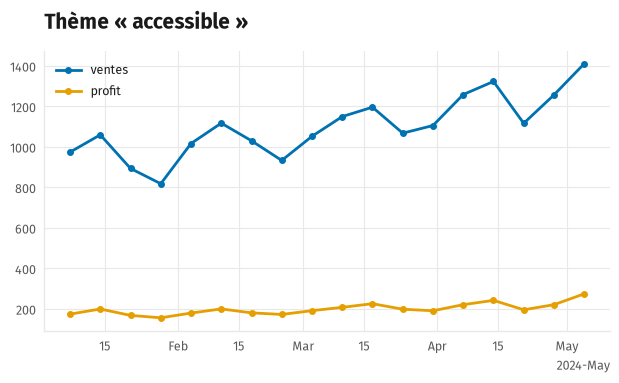

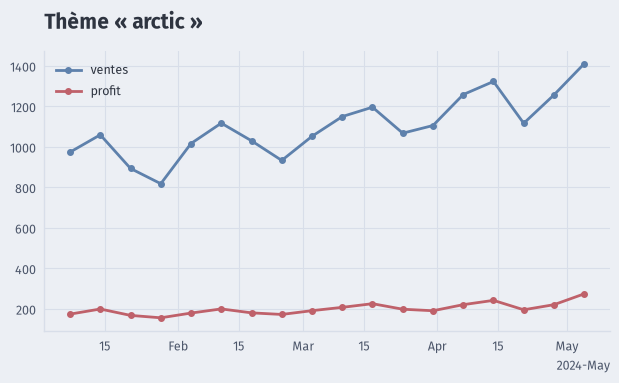

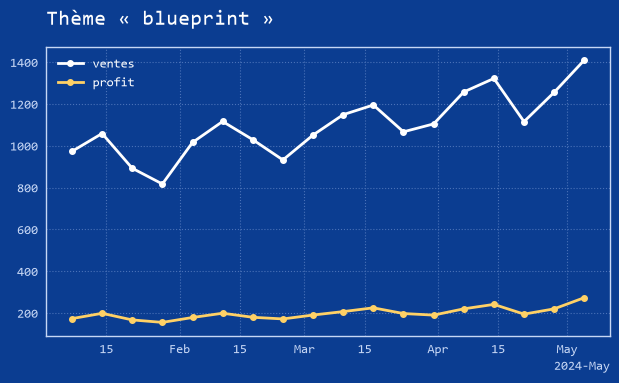

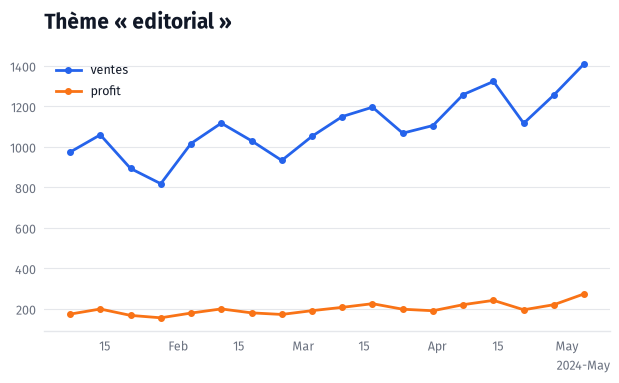

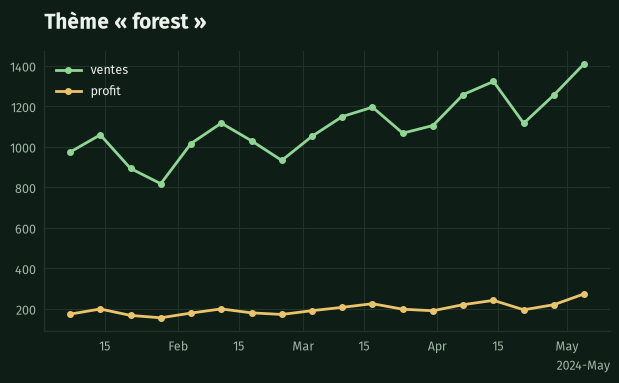

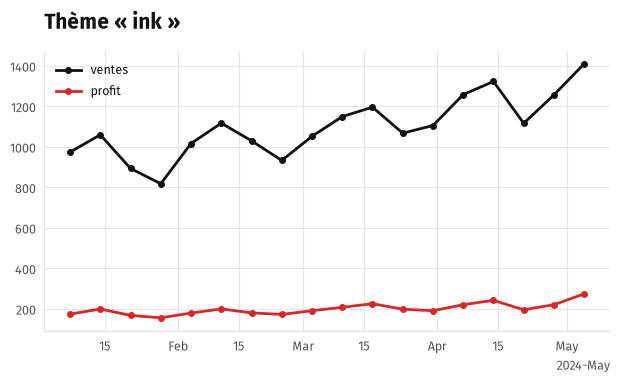

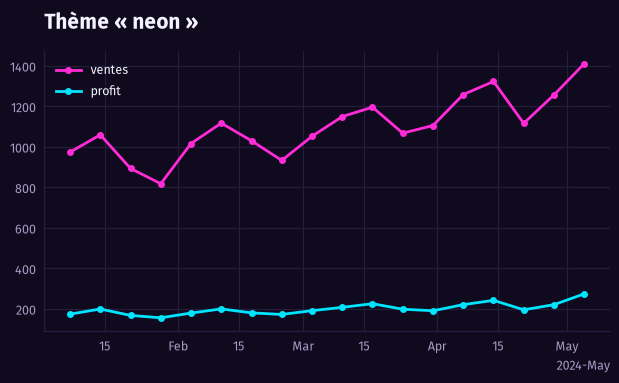

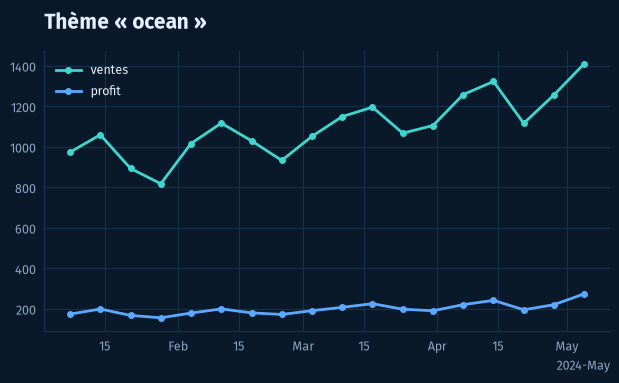

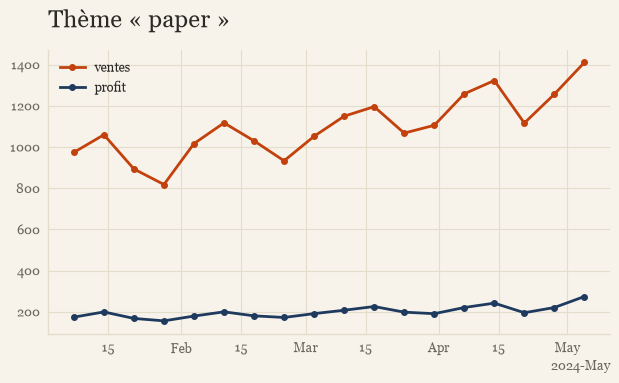

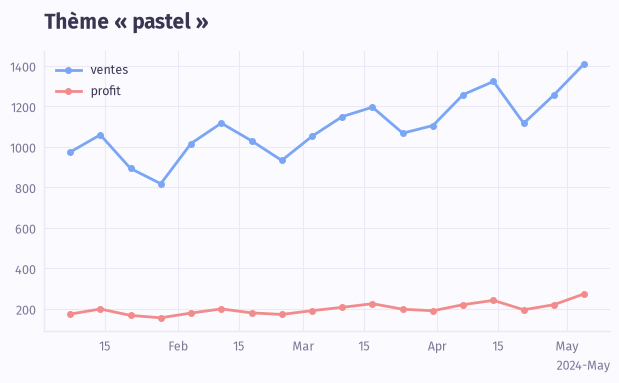

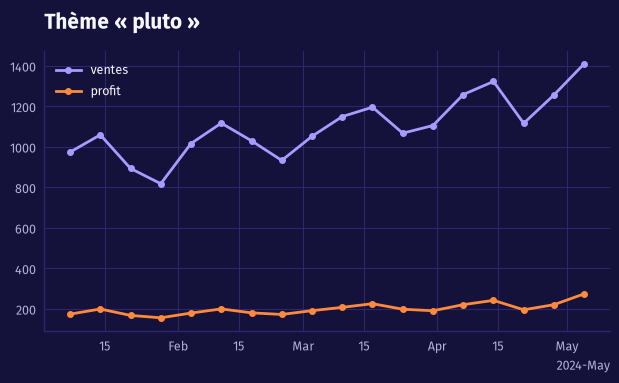

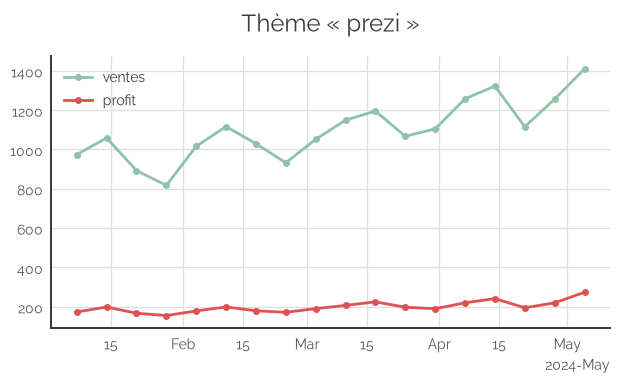

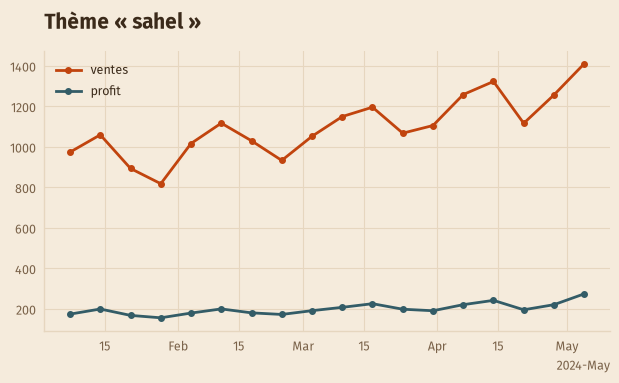

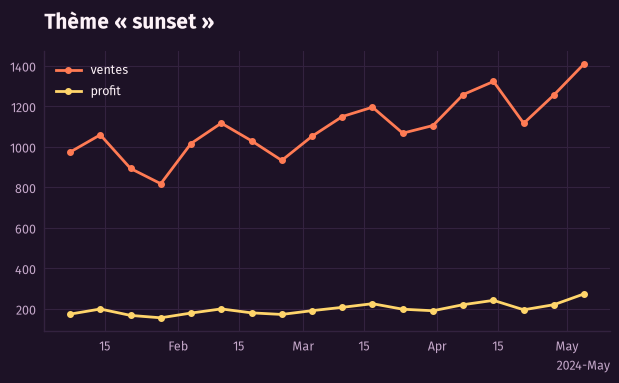

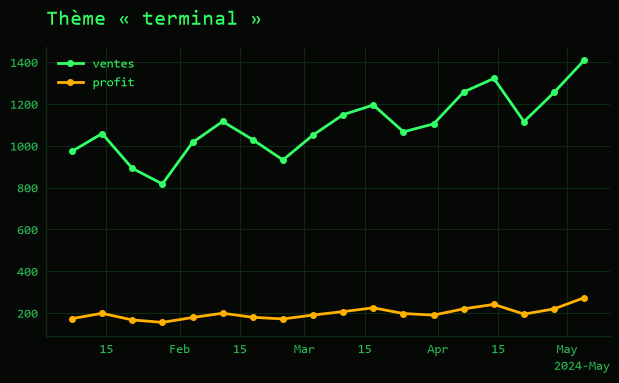

In [5]:
for nom in list_themes('plutovizu'):
    with theme_context(nom):
        (Chart(hebdo)
            .line('date', ['ventes', 'profit'], marker='o', markersize=4)
            .title(f'Thème « {nom} »')
            .set_legend()
            .tight_layout()
            .show())

Quelques styles seaborn et thèmes morethemes (les seconds téléchargent leur police au premier usage) :

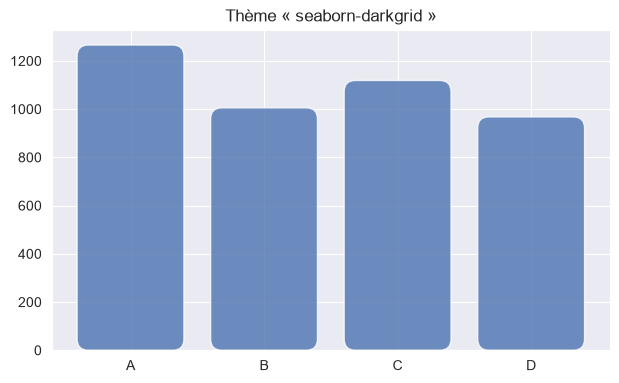

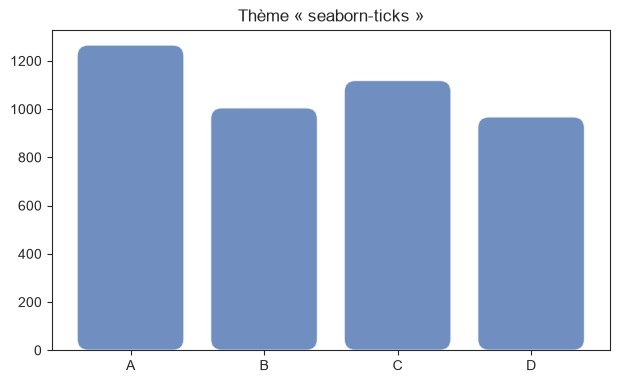

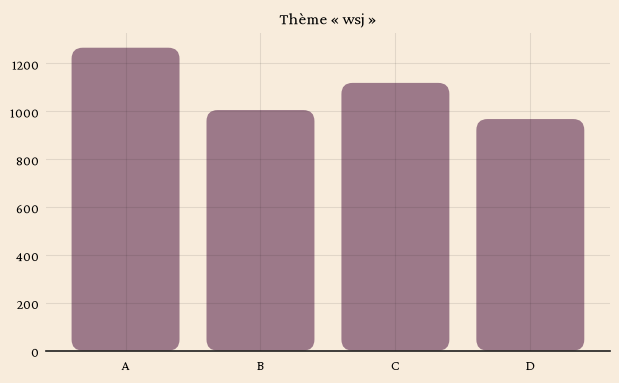

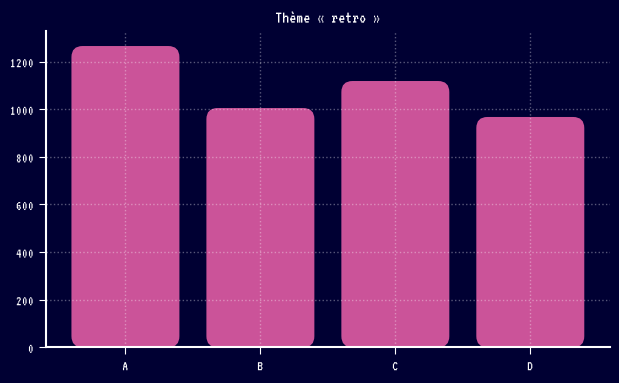

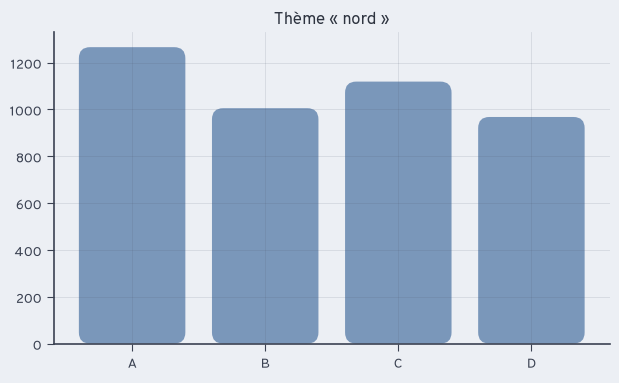

In [6]:
for nom in ['seaborn-darkgrid', 'seaborn-ticks', 'wsj', 'retro', 'nord']:
    with theme_context(nom):
        (Chart(par_categorie)
            .bar('categorie', 'ventes')
            .title(f'Thème « {nom} »')
            .tight_layout()
            .show())

`context` adapte la taille du texte au support (`'paper'`, `'notebook'`, `'talk'`, `'poster'`). `set_theme` applique un thème à toute la session ; `set_theme(None)` revient au style matplotlib.

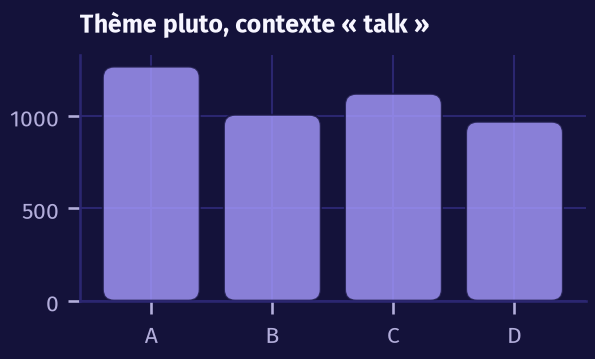

In [7]:
set_theme('pluto', context='talk')
(Chart(par_categorie)
    .bar('categorie', 'ventes')
    .title('Thème pluto, contexte « talk »')
    .tight_layout()
    .show())
set_theme()   # retour au thème par défaut (editorial)

## Palettes de couleurs

`set_colors` applique une palette à **ce** graphique (sans changer le thème des suivants).

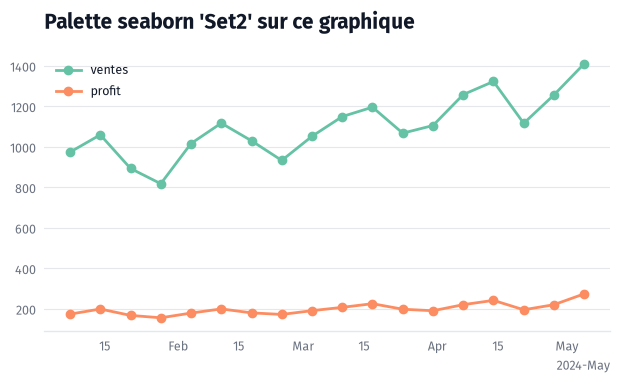

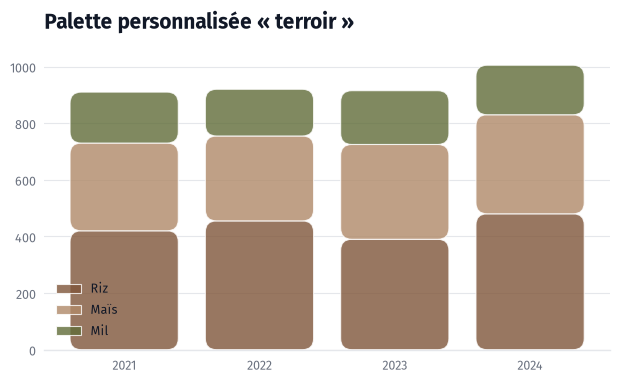

In [8]:
(Chart(hebdo)
    .set_colors('Set2')
    .line('date', ['ventes', 'profit'])
    .title("Palette seaborn 'Set2' sur ce graphique")
    .set_legend()
    .tight_layout()
    .show())

(Chart(production)
    .create_custom_palette('terroir', ['#7f5539', '#b08968', '#606c38'])
    .bar('annee', ['Riz', 'Maïs', 'Mil'], stacked=True)
    .title('Palette personnalisée « terroir »')
    .tight_layout()
    .show())

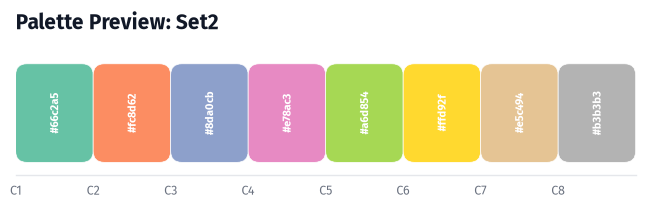

In [9]:
Chart(ventes, figsize=(8, 1.6)).preview_palette('Set2').show()

Plus de 2 700 palettes [pypalettes](https://github.com/y-sunflower/pypalettes) (MetBrewer, MoMAColors…) s'utilisent par leur nom ; `pypalette(nom, continuous=True)` en fait un dégradé pour les paramètres `cmap`.

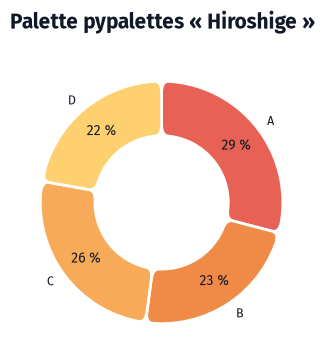

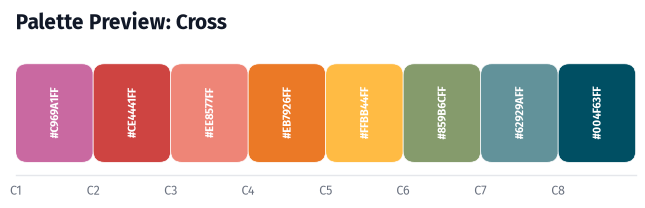

{'pypalettes_qualitative': 2002,
 'pypalettes_sequential': 328,
 'pypalettes_autre': 188,
 'pypalettes_diverging': 189}

In [10]:
from plutovizu import pypalette

(Chart(par_categorie)
    .set_colors('Hiroshige')
    .donut('ventes', labels='categorie')
    .title('Palette pypalettes « Hiroshige »')
    .show())

Chart(ventes, figsize=(8, 1.6)).preview_palette('Cross').show()
pals = Chart(ventes).get_available_palettes()
{k: len(v) for k, v in pals.items() if k.startswith('pypalettes')}

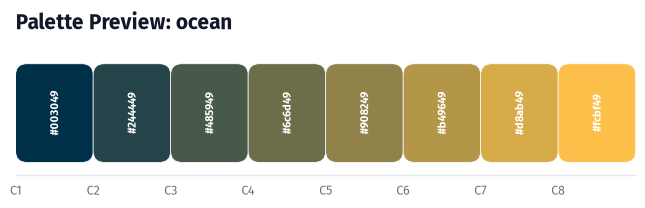

In [11]:
(Chart(ventes, figsize=(8, 1.6))
    .generate_gradient_palette('ocean', '#003049', '#fcbf49', n_colors=8)
    .preview_palette('ocean')
    .show())

## Polices, taille, annotations et coins arrondis

**Fira Sans** (police par défaut) et **Inter** sont fournies avec plutovizu. `load_font` (pyfonts) donne une police précise — fournie, ou téléchargée depuis Google Fonts. Un graphique mesure par défaut **16 × 10 cm** ; `cm()` convertit des centimètres.

Taille par défaut (cm) : [16.0, 10.0]


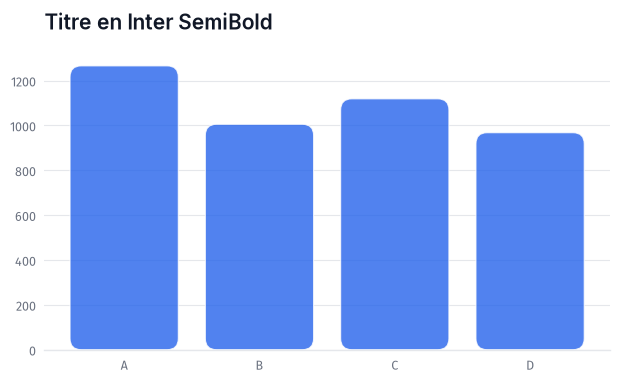

In [12]:
from plutovizu import FIGSIZE, cm, load_font

print('Taille par défaut (cm) :', [round(v * 2.54, 1) for v in FIGSIZE])
(Chart(par_categorie)
    .bar('categorie', 'ventes')
    .title('Titre en Inter SemiBold', fontproperties=load_font('Inter', 'semibold'))
    .tight_layout()
    .show())

In [13]:
get_fonts(pattern='Fira')

['Fira Sans', 'Fira Sans Light', 'Fira Sans Medium', 'Fira Sans SemiBold']

`font()` change la police globale ; une police absente du système est cherchée sur Google Fonts. On l'isole dans `plt.rc_context()` pour ne pas toucher aux graphiques suivants.

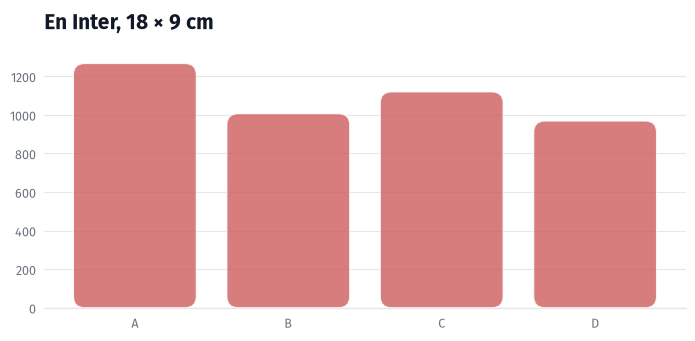

In [14]:
with plt.rc_context():
    (Chart(par_categorie, figsize=cm(18, 9))
        .font('Inter', size=11)
        .bar('categorie', 'ventes', color='indianred')
        .title('En Inter, 18 × 9 cm')
        .tight_layout()
        .show())

### Annotations (drawarrow)

`annotation` écrit un texte et trace une flèche courbe vers le point annoté ; `arrow` trace une flèche seule, en coordonnées des données, du graphique (`'axes'`) ou de la figure.

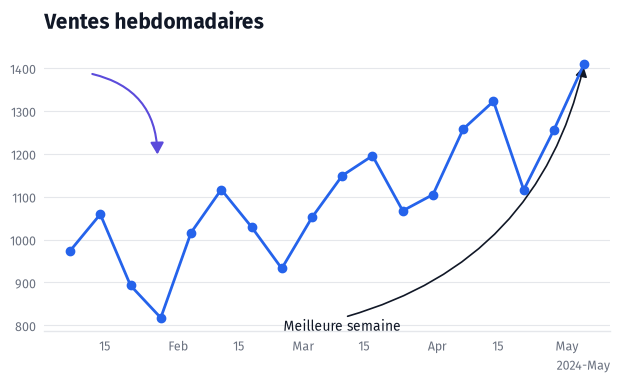

In [15]:
(Chart(hebdo)
    .line('date', 'ventes')
    .annotation('Meilleure semaine', xy=(hebdo.loc[hebdo['ventes'].idxmax(), 'date'], hebdo['ventes'].max()),
                xytext=(hebdo['date'].iloc[9], hebdo['ventes'].min()), radius=0.3)
    .arrow((0.08, 0.92), (0.2, 0.62), coords='axes', radius=-0.4, color='#5B4BDB')   # flèche seule
    .title('Ventes hebdomadaires')
    .tight_layout()
    .show())

### Coins arrondis

Tous les graphiques ont des coins arrondis de **8 points par défaut** (barres, histogrammes, camemberts, anneaux, barres radiales…). `rounded(r)` change le rayon, `rounded(0)` garde des coins vifs, `Chart.default_round = 0` désactive l'arrondi pour toute la session.

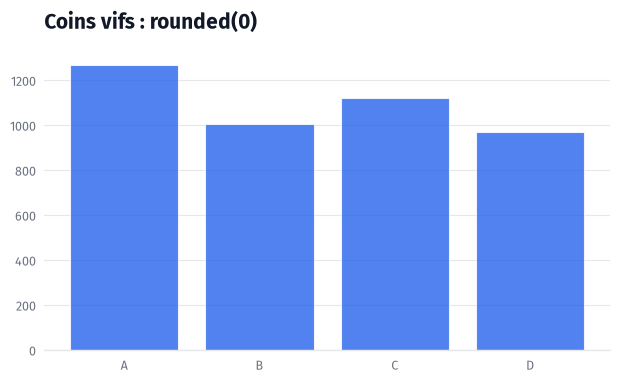

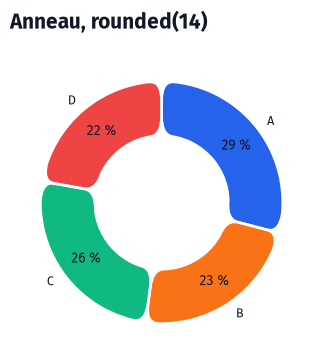

In [16]:
(Chart(par_categorie)
    .bar('categorie', 'ventes')
    .rounded(0)
    .title('Coins vifs : rounded(0)')
    .tight_layout()
    .show())

(Chart(par_categorie)
    .donut('ventes', labels='categorie')
    .rounded(14)
    .title('Anneau, rounded(14)')
    .show())

## Export

Appeler `save()` **avant** `show()` : `show()` ferme la figure pour libérer la mémoire.

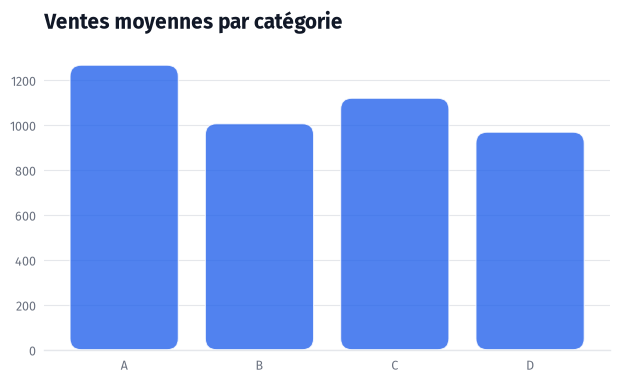

Enregistré : C:\Users\ORDINA~1\AppData\Local\Temp\ventes_par_categorie.png (23 Ko)


In [17]:
fichier = Path(tempfile.gettempdir()) / 'ventes_par_categorie.png'

(Chart(par_categorie, theme='editorial')
    .bar('categorie', 'ventes')
    .title('Ventes moyennes par catégorie')
    .tight_layout()
    .save(fichier, dpi=150)
    .show())
set_theme()   # retour au thème par défaut
print(f'Enregistré : {fichier} ({fichier.stat().st_size // 1024} Ko)')